# Libraries and Parameters

In [94]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks, medfilt, savgol_filter
from scipy.ndimage import binary_dilation
from scipy.optimize import curve_fit
from IPython.display import display

# Functions and tools

In [127]:
def load_fh(filename):     #Load a Franck-Hertz .dat file
    
    data = np.loadtxt(filename, usecols=(1,2)).T
    data[0] *= 10
    return data

def despike(data, window_V=1.0, thresh=0.1):
    """Remove short spikes (glitches) from UA.

    Points deviating more than `thresh` (V) from a running median of width
    `window_V` (in U2) are replaced by linear interpolation.
    Returns a 2 x N array (U2, UA_clean).
    """
    U2, UA = data
    dU = (U2.max() - U2.min()) / (len(U2) - 1)   # mean U2 step per sample
    n = int(window_V / dU) | 1
    bad = np.abs(UA - medfilt(UA, n)) > thresh
    bad = binary_dilation(bad, iterations=n // 10)   # also catch the spike flanks
    i = np.arange(len(UA))
    UA_clean = UA.copy()
    UA_clean[bad] = np.interp(i[bad], i[~bad], UA[~bad])
    return np.array([U2, UA_clean])

def find_extrema(data, smooth_V=0.5, min_sep_V=3.0, prominence=0.02, edge_V=1.0):
    """Find maxima and minima of a Franck-Hertz curve.

    Returns (maxima, minima, smoothed), all with row 0 = U2, row 1 = UA:
      maxima, minima: 2 x K arrays of the extrema coordinates
      smoothed:       2 x N array of the despiked, smoothed curve
    Extrema closer than edge_V to the end of the sweep are discarded.
    """
    U2, UA = despike(data)
    dU = (U2.max() - U2.min()) / (len(U2) - 1)   # U2 is noisy, so smooth along the sample index
    win = int(smooth_V / dU) | 1
    U2_s = savgol_filter(U2, win, 1)
    UA_s = savgol_filter(UA, win, 3)

    dist = int(min_sep_V / dU)
    imax, _ = find_peaks(UA_s,  distance=dist, prominence=prominence)
    imin, _ = find_peaks(-UA_s, distance=dist, prominence=prominence)
    imax = imax[U2_s[imax] < U2_s.max() - edge_V]
    imin = imin[U2_s[imin] < U2_s.max() - edge_V]

    maxima = np.array([U2_s[imax], UA_s[imax]])
    minima = np.array([U2_s[imin], UA_s[imin]])
    smoothed = np.array([U2_s, UA_s])
    return maxima, minima, smoothed

def contrast_snr(data, U_noise=3.0, max_gap_V=3.0):
    """Contrast C (eq. 5) and SNR_max (eq. 6) for every maximum.

    Each maximum is paired with the next minimum (if within max_gap_V).
    I_noise = std of UA for U2 < U_noise (before the current starts to rise).
    Returns a DataFrame with one row per order.
    """
    maxima, minima, _ = find_extrema(data)
    U2, UA = despike(data)
    I_noise = UA[U2 < U_noise].std()

    rows = []
    for U_max, I_max in maxima.T:
        nxt = minima[:, (minima[0] > U_max) & (minima[0] < U_max + max_gap_V)]
        if nxt.shape[1] == 0:
            continue
        I_min = nxt[1, 0]
        rows.append({"order": int(round(U_max / 4.9)),
                     "C": (I_max - I_min) / (I_max + I_min),
                     "SNR": I_max**2 / I_noise**2})
    return pd.DataFrame(rows)

# Calibrations

Text(0.5, 1.0, 'First Calibration')

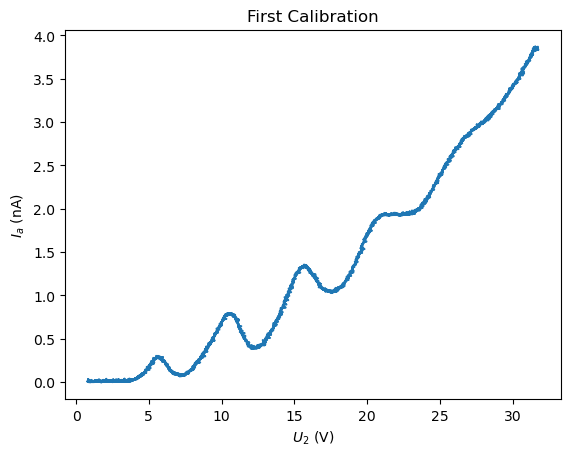

In [130]:
"""first calibration"""

dat_cal1 = load_fh("kha)(180C,U1=1.2,U3=2).dat")

plt.plot(*dat_cal1)
plt.xlabel("$U_2$ (V)")
plt.ylabel(r"$I_a$ (nA)")        # I_a = 1 nA · (U_a / V), FH box conversion
plt.title("First Calibration")

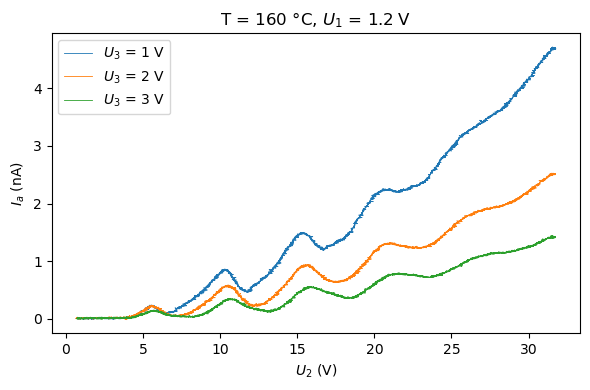

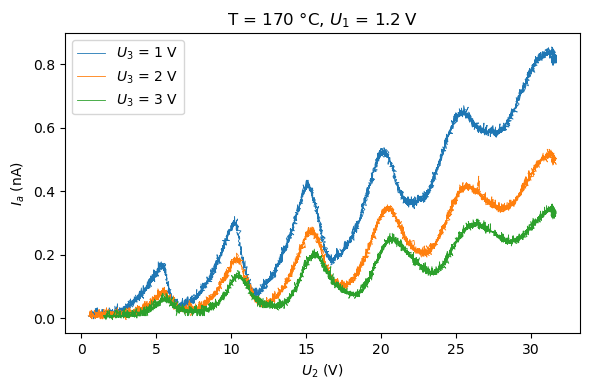

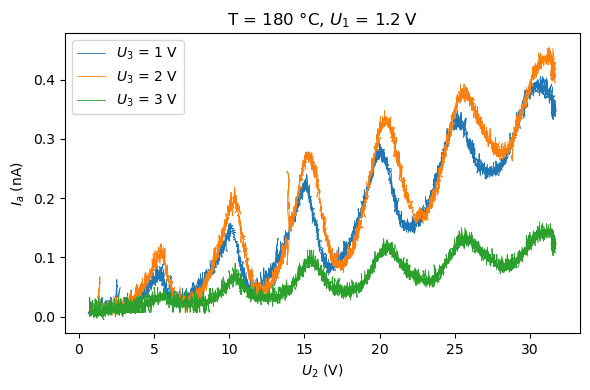

Contrast C per order:


order      1     2     3     4     5
T   U3                              
160 1   0.41  0.29  0.10   NaN   NaN
    2    NaN  0.42  0.18  0.03   NaN
    3   0.55  0.44  0.20  0.04   NaN
170 1   0.63  0.59  0.39  0.18  0.05
    2   0.55  0.61  0.46  0.26  0.09
    3   0.50  0.57  0.46  0.27  0.11
180 1   0.49  0.52  0.46  0.29  0.15
    2   0.63  0.64  0.52  0.33  0.16
    3    NaN  0.38  0.39  0.32  0.22

SNR_max per order:


order        1        2        3        4       5
T   U3                                           
160 1   1569.0  21836.0  65829.0      NaN     NaN
    2      NaN   8094.0  21590.0  42688.0     NaN
    3    404.0   2450.0   6432.0  12806.0     NaN
170 1    341.0   1113.0   2165.0   3365.0  5189.0
    2    168.0    795.0   1758.0   2779.0  3975.0
    3    148.0    693.0   1525.0   2403.0  3404.0
180 1     67.0    280.0    611.0    946.0  1350.0
    2    135.0    454.0    889.0   1293.0  1686.0
    3      NaN     97.0    192.0    283.0   357.0

mean C   min SNR  max U_A (V)
T   U3                               
160 1    0.267  1568.728        4.718
    2    0.212  8094.063        2.527
    3    0.308   404.421        1.445
170 1    0.369   340.646        0.855
    2    0.393   168.117        0.533
    3    0.381   148.055        0.377
180 1    0.383    66.724        1.395
    2    0.455   135.465        1.058
    3    0.325    97.451        0.160

Best combination: T = 180 °C, U3 = 2 V


In [132]:
"""Second Calibration (4.1b): U1 = 1.2 V, T = 160/170/180 C, U3 = 1/2/3 V"""

T_list  = [160, 170, 180]
U3_list = [1, 2, 3]

cal2 = {(T, U3): load_fh(f"khb)({T}C,U1=1.2,U3={U3}).dat") for T in T_list for U3 in U3_list}

# --- one plot per temperature, 3 braking voltages each ---
for T in T_list:
    fig, ax = plt.subplots(figsize=(6, 4))
    for U3 in U3_list:
        ax.plot(*despike(cal2[T, U3]), lw=0.6, label=f"$U_3$ = {U3} V")
    ax.set_xlabel("$U_2$ (V)")
    ax.set_ylabel(r"$I_a$ (nA)")      # I_a = 1 nA · (U_a / V), FH box conversion
    ax.set_title(f"T = {T} °C, $U_1$ = 1.2 V")
    ax.legend()
    fig.tight_layout()
    fig.savefig(f"cal2_{T}C.pdf")
    plt.show()

# --- contrast and SNR per order ---
cal2_res = pd.concat([contrast_snr(d).assign(T=T, U3=U3) for (T, U3), d in cal2.items()])

C_table   = cal2_res.pivot_table(index=["T", "U3"], columns="order", values="C")
SNR_table = cal2_res.pivot_table(index=["T", "U3"], columns="order", values="SNR")

summary = pd.DataFrame({
    "mean C":   C_table.mean(axis=1),
    "min SNR":  SNR_table.min(axis=1),
    "max U_A (V)": [cal2[k][1].max() for k in C_table.index],   # clipping check (ADC limit 5 V)
})

print("Contrast C per order:");  display(C_table.round(2))
print("SNR_max per order:");     display(SNR_table.round(0))
display(summary.round(3))

best = summary["mean C"].idxmax()
print(f"Best combination: T = {best[0]} °C, U3 = {best[1]} V")

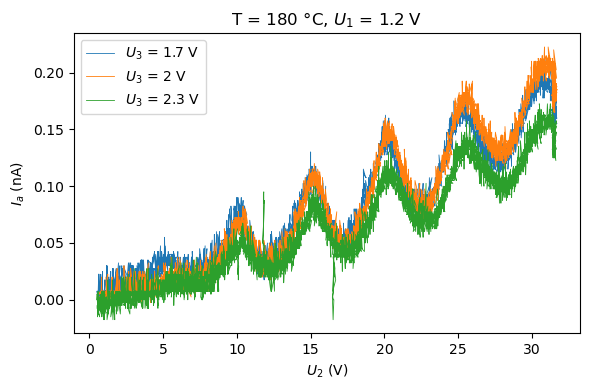

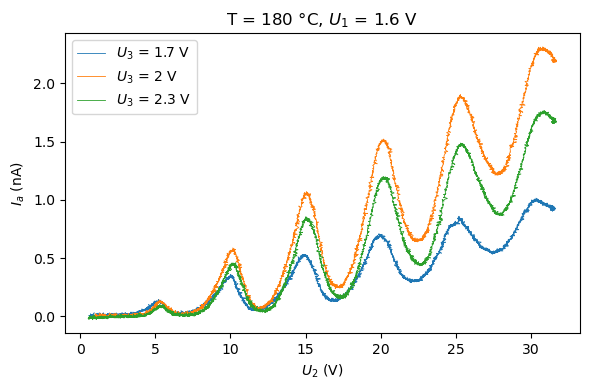

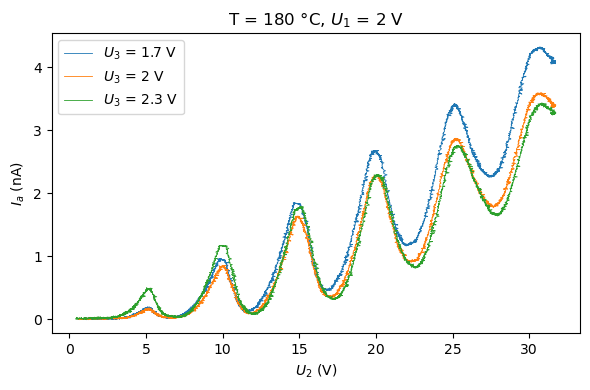

Contrast C per order:


order       1     2     3     4     5
U1  U3                               
1.2 1.7   NaN  0.38  0.36  0.26  0.15
    2.0   NaN  0.37  0.37  0.28  0.15
    2.3   NaN  0.41  0.47  0.25  0.15
1.6 1.7  0.66  0.73  0.59  0.39  0.21
    2.0   NaN  0.78  0.61  0.40  0.21
    2.3   NaN  0.82  0.67  0.46  0.26
2.0 1.7  0.79  0.78  0.60  0.39  0.20
    2.0  0.76  0.80  0.64  0.43  0.23
    2.3  0.86  0.87  0.69  0.47  0.25

SNR_max per order:


order         1        2         3         4         5
U1  U3                                                
1.2 1.7     NaN    128.0     260.0     431.0     589.0
    2.0     NaN    183.0     474.0     871.0    1279.0
    2.3     NaN     67.0     161.0     282.0     418.0
1.6 1.7   349.0   2498.0    5788.0   10015.0   14516.0
    2.0     NaN   7636.0   26325.0   53723.0   83896.0
    2.3     NaN   4458.0   15607.0   31389.0   48389.0
2.0 1.7  1166.0  32484.0  121705.0  254957.0  414624.0
    2.0   688.0  19597.0   73486.0  143808.0  226921.0
    2.3  2686.0  15842.0   36440.0   60560.0   87691.0

mean C   min SNR  max U_A (V)
U1  U3                                
1.2 1.7   0.290   127.569        0.213
    2.0   0.293   182.732        0.222
    2.3   0.320    67.101        0.172
1.6 1.7   0.515   348.633        1.015
    2.0   0.502  7636.013        2.312
    2.3   0.549  4458.197        1.765
2.0 1.7   0.552  1166.135        4.320
    2.0   0.573   687.929        3.590
    2.3   0.629  2686.383        3.430

Best combination: U1 = 2.0 V, U3 = 2.3 V


In [134]:
"""Third Calibration (4.1c): T = 180 C, U1 = 1.2/1.6/2 V, U3 = 1.7/2/2.3 V"""

U1_list  = [1.2, 1.6, 2]
U3c_list = [1.7, 2, 2.3]

cal3 = {(U1, U3): load_fh(f"khc)(180C,U1={U1},U3={U3}).dat") for U1 in U1_list for U3 in U3c_list}

# --- one plot per U1, 3 braking voltages each ---
for U1 in U1_list:
    fig, ax = plt.subplots(figsize=(6, 4))
    for U3 in U3c_list:
        ax.plot(*despike(cal3[U1, U3]), lw=0.6, label=f"$U_3$ = {U3} V")
    ax.set_xlabel("$U_2$ (V)")
    ax.set_ylabel(r"$I_a$ (nA)")      # I_a = 1 nA · (U_a / V), FH box conversion
    ax.set_title(f"T = 180 °C, $U_1$ = {U1} V")
    ax.legend()
    fig.tight_layout()
    fig.savefig(f"cal3_U1={U1}V.pdf")
    plt.show()

# --- contrast and SNR per order ---
cal3_res = pd.concat([contrast_snr(d).assign(U1=U1, U3=U3) for (U1, U3), d in cal3.items()])

C3_table   = cal3_res.pivot_table(index=["U1", "U3"], columns="order", values="C")
SNR3_table = cal3_res.pivot_table(index=["U1", "U3"], columns="order", values="SNR")

summary3 = pd.DataFrame({
    "mean C":   C3_table.mean(axis=1),
    "min SNR":  SNR3_table.min(axis=1),
    "max U_A (V)": [cal3[k][1].max() for k in C3_table.index],   # clipping check (ADC limit 5 V)
})

print("Contrast C per order:");  display(C3_table.round(2))
print("SNR_max per order:");     display(SNR3_table.round(0))
display(summary3.round(3))

best3 = summary3["mean C"].idxmax()
print(f"Best combination: U1 = {best3[0]} V, U3 = {best3[1]} V")

# Final Data Analysis

In [ ]:
"""Final data: 15 runs at T = 180 °C, U1 = 2 V, U3 = 2.3 V"""

fin = [load_fh(f"khd){n}.dat") for n in range(1, 16)]

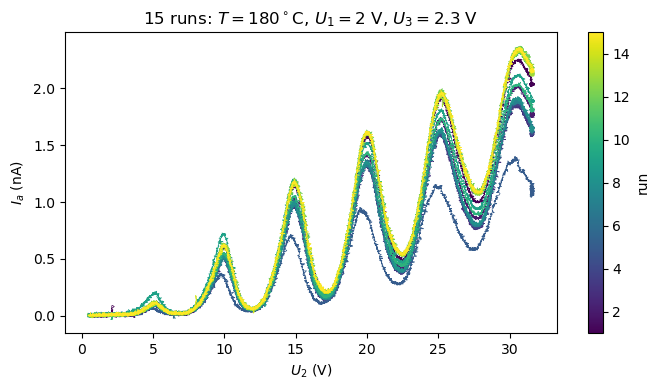

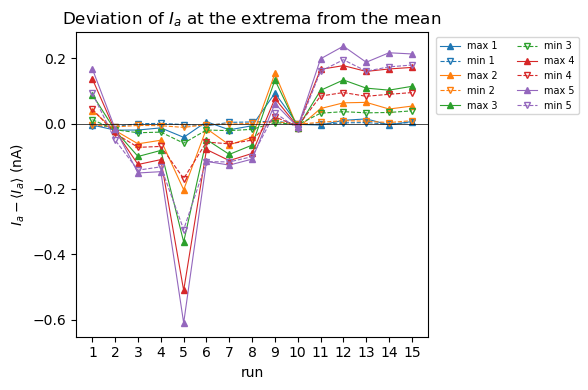

In [162]:
"""Drift check (report item 4): all 15 final runs overlaid + anode current at the extrema vs run"""

cmap   = plt.cm.viridis
colors = cmap(np.linspace(0, 1, len(fin)))

# --- figure 1: all 15 runs overlaid, colour = run order ---
fig, ax = plt.subplots(figsize=(7, 4))
for d, col in zip(fin, colors):
    ax.plot(*despike(d), color=col, lw=0.5)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(1, len(fin)))
fig.colorbar(sm, ax=ax, label="run")
ax.set_xlabel("$U_2$ (V)")
ax.set_ylabel(r"$I_a$ (nA)")      # I_a = 1 nA · (U_a / V), FH box conversion
ax.set_title(r"15 runs: $T = 180^\circ$C, $U_1 = 2$ V, $U_3 = 2.3$ V")
fig.tight_layout()
fig.savefig("final_15runs_overlay.pdf")
plt.show()

# --- figure 2: deviation of the anode current at each maximum / minimum from its mean over the 15 runs ---
runs = np.arange(1, len(fin) + 1)
ext  = [find_extrema(d) for d in fin]
I_mx = np.array([e[0][1, :5] for e in ext])      # 15 x 5, I_a at maxima (nA)
I_mn = np.array([e[1][1, :5] for e in ext])      # 15 x 5, I_a at minima (nA)

fig, ax = plt.subplots(figsize=(6, 4))
for j in range(5):
    ax.plot(runs, I_mx[:, j] - I_mx[:, j].mean(), "^-", color=f"C{j}", ms=4, lw=0.8, label=f"max {j+1}")
    ax.plot(runs, I_mn[:, j] - I_mn[:, j].mean(), "v--", color=f"C{j}", ms=4, lw=0.8, mfc="none", label=f"min {j+1}")
ax.axhline(0, color="k", lw=0.5)
ax.set_xticks(runs)
ax.set_xlabel("run")
ax.set_ylabel(r"$I_a - \langle I_a \rangle$ (nA)")      # I_a = 1 nA · (U_a / V), FH box conversion
ax.set_title(r"Deviation of $I_a$ at the extrema from the mean")
ax.legend(fontsize=7, ncol=2, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()
fig.savefig("final_15runs_drift.pdf")
plt.show()


In [164]:
"""4.2a: spacings between successive maxima / minima (15 runs, first 5 maxima and 5 minima each)"""


h_c = 1239.84   # h*c in eV nm

# U2 positions of the first 5 maxima and 5 minima of every run -> 15 x 5 arrays
U_max = np.array([find_extrema(d)[0][0, :5] for d in fin])
U_min = np.array([find_extrema(d)[1][0, :5] for d in fin])

# successive spacings -> 15 x 4 arrays (row = run, column = spacing k -> k+1)
dU_max = np.diff(U_max, axis=1)
dU_min = np.diff(U_min, axis=1)

def spacing_table(dU):
    n = dU.shape[0]
    mean, std = dU.mean(axis=0), dU.std(axis=0, ddof=1)
    lam = h_c / mean
    return pd.DataFrame({
        "spacing":              [f"{k}→{k+1}" for k in range(1, dU.shape[1] + 1)],
        "ΔU (V) = E (eV)":      mean,                   # E = e·ΔU
        "σ (V, eV)":            std,                    # std of the 15 runs
        "σ_mean (V, eV)":       std / np.sqrt(n),
        "λ (nm)":               lam,
        "σ_λ (nm)":             lam * std / mean,       # σ_λ = hc·σ_E / E²
        "σ_λ,mean (nm)":        lam * std / mean / np.sqrt(n),
    })

tab_max = spacing_table(dU_max)
tab_min = spacing_table(dU_min)

print("Maxima:"); display(tab_max.round(3))
print("Minima:"); display(tab_min.round(3))

Maxima:


,spacing,ΔU (V) = E (eV),"σ (V, eV)","σ_mean (V, eV)",λ (nm),σ_λ (nm),"σ_λ,mean (nm)"
0,1→2,4.833,0.027,0.007,256.524,1.422,0.367
1,2→3,4.928,0.017,0.004,251.595,0.861,0.222
2,3→4,5.096,0.073,0.019,243.315,3.505,0.905
3,4→5,5.199,0.061,0.016,238.472,2.818,0.728


Minima:


,spacing,ΔU (V) = E (eV),"σ (V, eV)","σ_mean (V, eV)",λ (nm),σ_λ (nm),"σ_λ,mean (nm)"
0,1→2,5.115,0.181,0.047,242.386,8.555,2.209
1,2→3,5.134,0.062,0.016,241.481,2.921,0.754
2,3→4,5.354,0.038,0.010,231.580,1.661,0.429
3,4→5,5.256,0.063,0.016,235.894,2.848,0.735


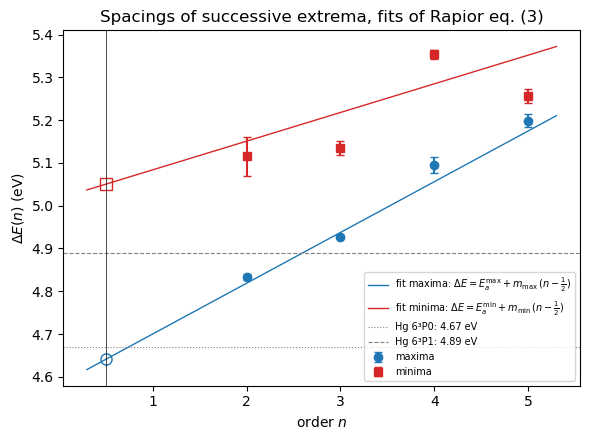

,E_a (eV),σ E_a (eV),σ E_a scaled (eV),m (eV),σ m (eV),σ m scaled (eV),χ²/ndf
maxima,4.6407,0.0126,0.0356,0.1187,0.0051,0.0144,7.9223
minima,5.0503,0.0363,0.2695,0.0671,0.0103,0.0767,55.2135


In [166]:
"""4.2b: Rapior et al. model -- fit eq. (3) to the spacings, E_a = ΔE(0.5) (eq. 4)"""

E_lit = {"6³P0 (265.6 nm)": 4.67, "6³P1 (253.7 nm)": 4.89}   # eV, level diagram (Fig. 2)

# spacing ΔE(n) between extremum n-1 and n  ->  n = 2..5 (first extremum = order 1)
n = np.arange(2, 2 + dU_max.shape[1])

def rapior(n, Ea, r):
    """Eq. (3): ΔE(n) = [1 + (2n - 1) λ/L] E_a,   r = λ/L"""
    return (1 + (2 * n - 1) * r) * Ea

def fit_rapior(dU):
    y  = dU.mean(axis=0)
    sy = dU.std(axis=0, ddof=1) / np.sqrt(dU.shape[0])      # std of the mean per spacing
    p, cov = curve_fit(rapior, n, y, p0=(4.7, 0.01), sigma=sy, absolute_sigma=True)
    chi2 = np.sum(((y - rapior(n, *p)) / sy) ** 2)
    return y, sy, p, np.sqrt(np.diag(cov)), cov, chi2 / (len(n) - 2)

res = {}
for name, dU in [("maxima", dU_max), ("minima", dU_min)]:
    y, sy, p, sp, cov, chi2r = fit_rapior(dU)
    slope   = 2 * p[0] * p[1]                                  # m = dΔE/dn = 2 E_a λ/L
    s_slope = 2 * np.sqrt(p[1]**2 * cov[0, 0] + p[0]**2 * cov[1, 1] + 2 * p[0] * p[1] * cov[0, 1])
    k = np.sqrt(max(chi2r, 1))                                 # PDG: inflate by √(χ²/ndf)
    res[name] = dict(y=y, sy=sy, p=p, cov=cov, slope=slope,
                     row={"E_a (eV)": p[0], "σ E_a (eV)": sp[0], "σ E_a scaled (eV)": sp[0] * k,
                          "m (eV)": slope, "σ m (eV)": s_slope, "σ m scaled (eV)": s_slope * k,
                          "χ²/ndf": chi2r})

# --- figure: spacings vs order + fits ΔE(n) = E_a + m (n - 1/2), extrapolated to n = 0.5 ---
fig, ax = plt.subplots(figsize=(6, 4.5))
nn = np.linspace(0.3, n.max() + 0.3, 200)
for (name, r), c, mk, sub in zip(res.items(), ["C0", "C3"], ["o", "s"], ["max", "min"]):
    Ea, m = r["p"][0], r["slope"]
    ax.errorbar(n, r["y"], yerr=r["sy"], fmt=mk, color=c, capsize=3, label=name)
    ax.plot(nn, Ea + m * (nn - 0.5), color=c, lw=1,
            label=rf"fit {name}: $\Delta E = E_a^{{\rm {sub}}} + m_{{\rm {sub}}}\,(n - \frac{{1}}{{2}})$")
    ax.plot(0.5, Ea, marker=mk, mfc="none", color=c, ms=8)
for (lab, E), ls in zip(E_lit.items(), [":", "--"]):
    ax.axhline(E, color="grey", ls=ls, lw=0.8, label=f"Hg {lab.split()[0]}: {E} eV")
ax.axvline(0.5, color="k", lw=0.5)
ax.set_xlabel("order $n$")
ax.set_ylabel(r"$\Delta E(n)$ (eV)")
ax.set_title("Spacings of successive extrema, fits of Rapior eq. (3)")
ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig("rapior_fit.pdf")
plt.show()

# --- table: fit parameters ---
fit_tab = pd.DataFrame({k: v["row"] for k, v in res.items()}).T
display(fit_tab.round(4))


In [141]:
"""4.2c: Planck constant from eq. (2): E_a = h c / λ  ->  h = E_a λ / c"""

from scipy.constants import e, c

h_lit = 6.62607015e-34                                   # J s (exact, SI)
lam_lit = {"6³P0": (265.6e-9, 4.67), "6³P1": (253.7e-9, 4.89)}   # theoretical λ (m), E (eV)

rows = []
for name in ["maxima", "minima"]:
    r = res[name]["row"]
    Ea = r["E_a (eV)"]
    # transition whose energy is closest to the measured E_a
    line = min(lam_lit, key=lambda k: abs(lam_lit[k][1] - Ea))
    lam = lam_lit[line][0]
    h = Ea * e * lam / c                                 # λ taken as exact -> σ_h / h = σ_E / E
    for label, sE in [("fit", r["σ E_a (eV)"]), ("scaled", r["σ E_a scaled (eV)"])]:
        sh = h * sE / Ea
        rows.append({"extrema": name, "σ type": label,
                     "E_a (eV)": Ea, "σ E_a (eV)": sE,
                     "line": line, "λ (nm)": lam * 1e9,
                     "h (1e-34 J s)": h / 1e-34, "σ h (1e-34 J s)": sh / 1e-34,
                     "rel. σ (%)": 100 * sh / h,
                     "h - h_lit (1e-34 J s)": (h - h_lit) / 1e-34,
                     "deviation (%)": 100 * (h - h_lit) / h_lit,
                     "z = |h - h_lit| / σ": abs(h - h_lit) / sh})

h_tab = pd.DataFrame(rows).set_index(["extrema", "σ type"])
display(h_tab.round(3))

E_a (eV)  σ E_a (eV)  line  λ (nm)  h (1e-34 J s)  \
extrema σ type                                                      
maxima  fit        4.641       0.013  6³P0   265.6          6.587   
        scaled     4.641       0.036  6³P0   265.6          6.587   
minima  fit        5.050       0.036  6³P1   253.7          6.847   
        scaled     5.050       0.269  6³P1   253.7          6.847   

                σ h (1e-34 J s)  rel. σ (%)  h - h_lit (1e-34 J s)  \
extrema σ type                                                       
maxima  fit               0.018       0.272                 -0.039   
        scaled            0.050       0.766                 -0.039   
minima  fit               0.049       0.718                  0.221   
        scaled            0.365       5.336                  0.221   

                deviation (%)  z = |h - h_lit| / σ  
extrema σ type                                      
maxima  fit            -0.586                2.164  
        scaled         -0.586                0.769  
minima  fit             3.340                4.501  
        scaled          3.340                0.606